### Procesamiento de Lenguaje Natural I
# **Desafío 1**



#### **Alumno 1:** Lerner, Federico Ezequiel - a2619

#### **Alumno 2:** Makk, Azul de los Angeles - a2622

In [1]:
%pip install numpy scikit-learn

### Vectorización de texto y modelo de clasificación Naïve Bayes con el dataset 20 newsgroups

In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import f1_score

Utilizamos **20newsgroups** por ser un dataset clásico de NLP ya viene incluido y formateado en sklearn

In [3]:
from sklearn.datasets import fetch_20newsgroups
import numpy as np

## Carga de datos

Cargamos los datos (ya separados de forma predeterminada en train y test)

El dataset 20 Newsgroups contiene aproximadamente 18 000 publicaciones de grupos de noticias distribuidas en 20 temas. Está dividido en dos subconjuntos: uno para entrenamiento (train set) y otro para pruebas (test set).

In [4]:
newsgroups_train = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
newsgroups_test = fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))

## Vectorización

Instanciamos un vectorizador.

Podemos ver diferentes parámetros de instanciación en la documentación de sklearn https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

In [5]:
tfidfvect = TfidfVectorizer()

En el atributo `data` accedemos al texto

In [6]:
print(newsgroups_train.data[0])

I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


Con la interfaz habitual de sklearn podemos ajustar el vectorizador (obtener el vocabulario y calcular el vector IDF) y transformar directamente los datos.

Podemos denominar `X_train` como la matriz documento-término.

In [7]:
X_train = tfidfvect.fit_transform(newsgroups_train.data)

Recordemos que las vectorizaciones por conteos son de tipo sparse, por ello sklearn convenientemente devuelve los vectores de documentos como matrices de tipo sparse.

In [8]:
print(type(X_train))
print(f'shape: {X_train.shape}')
print(f'Cantidad de documentos: {X_train.shape[0]}')
print(f'Tamaño del vocabulario (dimensionalidad de los vectores): {X_train.shape[1]}')

<class 'scipy.sparse._csr.csr_matrix'>
shape: (11314, 101631)
Cantidad de documentos: 11314
Tamaño del vocabulario (dimensionalidad de los vectores): 101631


Una vez ajustado el vectorizador, podemos acceder a atributos como el vocabulario aprendido. Es un diccionario que va de términos a índices.

El índice es la posición en el vector de documento.

In [9]:
tfidfvect.vocabulary_['car']

25775

Probamos con una palbra que no está en el documento.

In [10]:
# tfidfvect.vocabulary_['cocoliso']

Es muy útil tener el diccionario opuesto que va de índices a términos

In [11]:
idx2word = {v: k for k,v in tfidfvect.vocabulary_.items()}

En `y_train` guardamos los targets que son enteros

In [12]:
y_train = newsgroups_train.target
y_train[:10]

array([ 7,  4,  4,  1, 14, 16, 13,  3,  2,  4])

Hay 20 clases correspondientes a los 20 grupos de noticias

In [13]:
print(f'clases {np.unique(newsgroups_test.target)}')
newsgroups_test.target_names

clases [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

## Similaridad de documentos

Veamos similaridad de documentos. Tomemos algún documento

In [14]:
idx = 4811
print(newsgroups_train.data[idx])

THE WHITE HOUSE

                  Office of the Press Secretary
                   (Pittsburgh, Pennslyvania)
______________________________________________________________
For Immediate Release                         April 17, 1993     

             
                  RADIO ADDRESS TO THE NATION 
                        BY THE PRESIDENT
             
                Pittsburgh International Airport
                    Pittsburgh, Pennsylvania
             
             
10:06 A.M. EDT
             
             
             THE PRESIDENT:  Good morning.  My voice is coming to
you this morning through the facilities of the oldest radio
station in America, KDKA in Pittsburgh.  I'm visiting the city to
meet personally with citizens here to discuss my plans for jobs,
health care and the economy.  But I wanted first to do my weekly
broadcast with the American people. 
             
             I'm told this station first broadcast in 1920 when
it reported that year's presidential elec

Medimos la similaridad coseno con todos los documentos de train

In [15]:
cossim = cosine_similarity(X_train[idx], X_train)[0]

Podemos ver los valores de similaridad ordenados de mayor a menor

In [16]:
np.sort(cossim)[::-1]

array([1.        , 0.70930477, 0.67474953, ..., 0.        , 0.        ,
       0.        ], shape=(11314,))

Después vemos a qué documentos corresponden

In [17]:
np.argsort(cossim)[::-1]

array([ 4811,  6635,  4253, ...,  1534, 10055,  4750], shape=(11314,))

Obtenemos los 5 documentos más similares:

In [18]:
mostsim = np.argsort(cossim)[::-1][1:6]
print(mostsim)

[6635 4253 3596 4271 3746]


El documento original pertenece a la clase:

In [19]:
newsgroups_train.target_names[y_train[idx]]

'talk.politics.misc'

Revisamos las clases de los 5 más similares:

In [20]:
for i in mostsim:
  print(newsgroups_train.target_names[y_train[i]])

talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc


### Modelo de clasificación Naïve Bayes

Instanciamos el modelo de clasificación Naive Bayes y lo entrenamos con sklearn

In [21]:
clf = MultinomialNB()
clf.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](20,)","[480.,584.,591.,...,564.,465.,377.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](20,)","[-3.16,-2.96,-2.95,...,-3. ,-3.19,-3.4 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](20,)","[ 0, 1, 2,...,17,18,19]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](20, 101631)","[[0. ,0.94,0. ,...,0. ,0. ,0. ], [1.39,0.6 ,0. ,...,0. ,0. ,0. ], [0.95,0.14,0. ,...,0. ,0. ,0. ], ..., [0.42,2.9 ,0.04,...,0. ,0. ,0. ], [0.61,1.36,0. ,...,0. ,0. ,0. ], [0.03,0.38,0. ,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](20, 101631)","[[-11.56,-10.9 ,-11.56,...,-11.56,-11.56,-11.56], [-10.69,-11.1 ,-11.56,...,-11.56,-11.56,-11.56], [-10.9 ,-11.44,-11.57,...,-11.57,-11.57,-11.57], ..., [-11.22,-10.21,-11.54,...,-11.57,-11.57,-11.57], [-11.09,-10.7 ,-11.56,...,-11.56,-11.56,-11.56], [-11.53,-11.23,-11.56,...,-11.56,-11.56,-11.56]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,101631


Ya tenemos nuestro vectorizador ya ajustado en train, vectorizamos los textos
del conjunto de test.

In [22]:
X_test = tfidfvect.transform(newsgroups_test.data)
y_test = newsgroups_test.target
y_pred =  clf.predict(X_test)

El F1-score es una métrica adecuada para evaluar el desempeño de modelos de clasificación, especialmente cuando existe desbalance entre clases.

* El promediado macro calcula el promedio del F1-score de cada clase, otorgando el mismo peso a todas las clases.
* El promediado micro calcula las métricas de forma global considerando todas las predicciones; en problemas de clasificación multiclase suele ser equivalente a la accuracy, por lo que no es la mejor métrica cuando el dataset está desbalanceado.

In [23]:
f1_score(y_test, y_pred, average='macro')

0.5854345727938506

---

## **Consigna del Desafío 1**
**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado.**



**1. Vectorizar documentos**
* Tomar 5 documentos al azar y medir similaridad con el resto de los documentos.
Estudiar los 5 documentos más similares de cada uno analizar si tiene sentido
la similaridad según el contenido del texto y la etiqueta de clasificación.

**2. Construir un modelo de clasificación por prototipos (tipo zero-shot).**
* Clasificar los documentos de un conjunto de test comparando cada uno con todos los de entrenamiento y asignar la clase al label del documento del conjunto de entrenamiento con mayor similaridad.

**3. Entrenar modelos de clasificación Naïve Bayes para maximizar el desempeño de clasificación**

* F1-Score Macro en el conjunto de datos de test. Considerar cambiar parámetros
de instanciación del vectorizador y los modelos y probar modelos de Naïve Bayes Multinomial y ComplementNB.

**NO cambiar el hiperparámetro ngram_range de los vectorizadores**.

**4. Transponer la matriz documento-término.**
* De esa manera se obtiene una matriz término-documento que puede ser interpretada como una colección de vectorización de palabras.
* Estudiar ahora similaridad entre palabras tomando 5 palabras y estudiando sus 5 más similares.

**Elegir las palabras MANUALMENTE para evitar la aparición de términos poco interpretables**.


---
# **Resolución**

Las siguientes decisiones aplican a todo el notebook:

- Se utilizan los mismos datos que en la plantilla (`remove=('headers', 'footers', 'quotes')`), de modo que los resultados sean comparables con el baseline incluido en ella.
- Se fijan semillas aleatorias para que los documentos seleccionados "al azar" sean siempre los mismos y el análisis escrito coincida con los resultados obtenidos al ejecutar el notebook.
- Se respeta la restricción de la consigna: no se modifica `ngram_range` en ningún vectorizador, que permanece en su valor por defecto `(1, 1)`.
- La métrica común de comparación es el F1-score macro sobre el conjunto de test.

In [24]:
%pip install -q nltk pandas matplotlib

In [25]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import normalize

pd.set_option('display.max_colwidth', 120)

class_names = newsgroups_train.target_names
y_train = newsgroups_train.target
y_test = newsgroups_test.target

### Análisis exploratorio inicial

Antes de calcular similitudes analizamos dos aspectos del dataset que luego permitieron explicar varios resultados: la cantidad de documentos que quedan vacíos o casi vacíos al eliminar encabezados, pies y citas, y la distribución de las clases.

In [26]:
largos_train = np.array([len(d.split()) for d in newsgroups_train.data])
largos_test = np.array([len(d.split()) for d in newsgroups_test.data])

print(f'Docs de train vacíos: {(largos_train == 0).sum()}  |  con menos de 10 palabras: {(largos_train < 10).sum()}')
print(f'Docs de test vacíos:  {(largos_test == 0).sum()}  |  con menos de 10 palabras: {(largos_test < 10).sum()}')
print(f'Mediana de palabras por documento (train): {np.median(largos_train):.0f}')

pd.Series(np.bincount(y_train), index=class_names, name='docs en train').sort_values()

Docs de train vacíos: 300  |  con menos de 10 palabras: 607
Docs de test vacíos:  215  |  con menos de 10 palabras: 447
Mediana de palabras por documento (train): 83


talk.religion.misc          377
talk.politics.misc          465
alt.atheism                 480
talk.politics.guns          546
talk.politics.mideast       564
comp.sys.mac.hardware       578
comp.graphics               584
misc.forsale                585
comp.sys.ibm.pc.hardware    590
comp.os.ms-windows.misc     591
sci.electronics             591
comp.windows.x              593
sci.space                   593
rec.autos                   594
sci.med                     594
sci.crypt                   595
rec.sport.baseball          597
rec.motorcycles             598
soc.religion.christian      599
rec.sport.hockey            600
Name: docs en train, dtype: int64

In [27]:
# contenido original de los documentos que quedan vacíos (sin eliminar citas ni pies)
train_con_citas = fetch_20newsgroups(subset='train', remove=('headers',))
vacios_train = np.where(largos_train == 0)[0]

def tiene_cita(texto):
    return any(l.lstrip().startswith(('>', '|', ':')) or 'writes:' in l or 'wrote:' in l for l in texto.splitlines())

print(f'Docs vacíos de train que contenían citas: {sum(tiene_cita(train_con_citas.data[i]) for i in vacios_train)} de {len(vacios_train)}')

Docs vacíos de train que contenían citas: 282 de 300


300 documentos de train y 215 de test quedan completamente vacíos al eliminar encabezados, pies y citas. En train verificamos que 282 de esos 300 contenían citas: en su gran mayoría son respuestas cuyo contenido era solo la cita del mensaje anterior. Este aspecto resulta relevante en el punto 2, donde se observan 237 vectores nulos en test: a los documentos vacíos se suman aquellos cuyas palabras son todas stopwords o no forman parte del vocabulario de train.

Las clases se encuentran razonablemente balanceadas (la mayoría tiene entre 545 y 600 documentos), con excepción de `talk.religion.misc` (377), `alt.atheism` (480) y `talk.politics.misc` (465). Por eso resulta adecuado utilizar el F1 macro, que asigna el mismo peso a las clases minoritarias que al resto.

---
## **1. Vectorizar documentos y similaridad**

Además de identificar los documentos más similares, experimentamos con los parámetros del vectorizador (la consigna lo pide explícitamente para el punto 3, pero también afecta a la similaridad). El `TfidfVectorizer()` de la plantilla se utiliza con los parámetros por defecto, por lo que el vocabulario supera los 100.000 términos e incluye todas las stopwords. Evaluamos la siguiente configuración:

- `stop_words='english'`: elimina las palabras vacías ("the", "and", "is", etc.). Por la ley de Zipf, unas pocas palabras concentran gran parte de las apariciones; estas palabras aparecen en prácticamente todos los textos y no contribuyen a distinguir temas.
- `min_df=2`: descarta los términos que aparecen en un único documento. En general corresponden a errores de tipeo, códigos o números aislados que no relacionan documentos entre sí (por ejemplo, números de documento o de pasaporte).
- `max_df=0.5`: descarta los términos presentes en más de la mitad de los documentos, como forma complementaria de eliminar palabras demasiado frecuentes que no figuren en la lista de stopwords.
- `sublinear_tf=True`: reemplaza el conteo bruto por `1 + log(tf)`. Cuando un mensaje repite muchas veces una misma palabra (algo habitual en listados o fragmentos de código), se evita que esa palabra domine el vector.

In [28]:
vect_sim = TfidfVectorizer(stop_words='english', min_df=2, max_df=0.5, sublinear_tf=True)
X_train_sim = vect_sim.fit_transform(newsgroups_train.data)
vocab_sim = vect_sim.get_feature_names_out()

print(f'Vocabulario plantilla (por defecto):   {X_train.shape[1]} términos')
print(f'Vocabulario con nuestros parámetros:   {X_train_sim.shape[1]} términos')

Vocabulario plantilla (por defecto):   101631 términos
Vocabulario con nuestros parámetros:   39115 términos


El vocabulario se reduce de aproximadamente 101.000 a 39.000 términos. La mayor parte de los términos eliminados son aquellos que aparecen en un solo documento (efecto de `min_df=2`).

Para comprender por qué dos documentos resultan similares, definimos una función que identifica los términos que más contribuyen a la similaridad. Dado que TF-IDF normaliza cada vector con norma L2, la similaridad coseno equivale al producto escalar, es decir, a la suma de `peso_doc1(t) * peso_doc2(t)` sobre todos los términos `t`. Los términos con mayor producto son los que explican la similitud entre ambos documentos.

In [29]:
def terminos_en_comun(X, i, j, vocab, n=5):
    """Términos que más aportan al coseno entre los documentos i y j."""
    prod = X[i].multiply(X[j]).toarray().ravel()
    orden = np.argsort(prod)[::-1][:n]
    return [vocab[k] for k in orden if prod[k] > 0]


def mostrar_similares(idx, X, data, y, vocab, k=5, largo=350):
    sims = cosine_similarity(X[idx], X).ravel()
    sims[idx] = -1  # sacamos al propio documento (similaridad 1 consigo mismo)
    top = np.argsort(sims)[::-1][:k]

    print(f'DOCUMENTO {idx}  |  clase: {class_names[y[idx]]}  |  {len(data[idx].split())} palabras')
    print('-' * 100)
    print(data[idx][:600].strip())
    print('-' * 100)
    filas = []
    for j in top:
        filas.append({
            'doc': j,
            'similaridad': round(sims[j], 3),
            'clase': class_names[y[j]],
            'misma clase': y[j] == y[idx],
            'términos que más aportan': terminos_en_comun(X, idx, j, vocab),
            'inicio del texto': ' '.join(data[j].split())[:largo],
        })
    return pd.DataFrame(filas)

In [30]:
rng = np.random.default_rng(42)
docs_elegidos = rng.choice(len(newsgroups_train.data), 5, replace=False)
docs_elegidos

array([8754, 4965, 7404, 1009, 4899])

### Documento 1

In [31]:
mostrar_similares(docs_elegidos[0], X_train_sim, newsgroups_train.data, y_train, vocab_sim)

DOCUMENTO 8754  |  clase: talk.religion.misc  |  565 palabras
----------------------------------------------------------------------------------------------------
/(hudson)
/If someone inflicts pain on themselves, whether they enjoy it or not, they
/are hurting themselves.  They may be permanently damaging their body.

That is true.  It is also none of your business.  

Some people may also reason that by reading the bible and being a Xtian
you are permanently damaging your brain.  By your logic, it would be OK
for them to come into your home, take away your bible, and send you off
to "re-education camps" to save your mind from ruin.  Are you ready for
that?  





/(hudson)
/And why is there nothing wrong with it?  Because you say so?  Who gave you
/t
----------------------------------------------------------------------------------------------------


,doc,similaridad,clase,misma clase,términos que más aportan,inicio del texto
0,5966,0.243,talk.religion.misc,True,"[hudson, moral, morality, pain, choice]",(hudson) (me) /(hudson) /So. Why is someone elses will such a big deal if morality is all relative. I don't believe ...
1,10613,0.223,talk.religion.misc,True,"[hudson, moral, morality, interfere, morally]",/(hudson) /Yes you do. Who is to say that it is immoral for onesself to experience /pain or to be hurt in some other...
2,590,0.221,talk.religion.misc,True,"[hudson, moral, pain, choices, force]",/(me) /(hudson) /Why does that make something immoral? Because you are not being consistent. Moral systems must be c...
3,10184,0.185,talk.religion.misc,True,"[hudson, moral, morality, people, right]","/(hudson) /If all morality were relative- big hairy deal. As I said, you appear to be the only person saying that al..."
4,4355,0.184,alt.atheism,False,"[interfere, interference, morality, moral, rules]",#In <1qvabj$g1j@horus.ap.mchp.sni.de> frank@D012S658.uucp (Frank O'Dwyer) # #>In article <C5qGM3.DL8@news.cso.uiuc.e...


**Documento 8754 (`talk.religion.misc`).** Se trata de un mensaje extenso (565 palabras) perteneciente a una discusión sobre si la moral es relativa o absoluta. En este caso el método funciona bien: 4 de los 5 vecinos pertenecen a la misma clase y el quinto, de `alt.atheism`, aborda el mismo tema (moral, interferencia, reglas).

El análisis de los términos que más contribuyen revela un aspecto no esperado: en los 4 primeros vecinos el término de mayor aporte es "hudson", el nombre del usuario con quien se mantiene la discusión. Por su contenido, estos 4 vecinos parecen formar parte de la misma conversación. Es decir, la similaridad captura el tema, pero en parte porque identifica mensajes de una misma discusión. Un nombre propio no aporta información temática, pero al aparecer en pocos documentos su IDF es alto y su peso resulta considerable.

Como buscador de documentos relacionados, el resultado es bueno; como evidencia de que el método capta el contenido religioso, es más débil de lo que aparenta.

### Documento 2

In [32]:
mostrar_similares(docs_elegidos[1], X_train_sim, newsgroups_train.data, y_train, vocab_sim)

DOCUMENTO 4965  |  clase: comp.sys.mac.hardware  |  16 palabras
----------------------------------------------------------------------------------------------------
No.  Plug the printer in the printer port, and the modem in the modem
port. ;)
----------------------------------------------------------------------------------------------------


,doc,similaridad,clase,misma clase,términos que más aportan,inicio del texto
0,9736,0.364,comp.sys.mac.hardware,True,"[port, printer, modem]","I have used both my serial ports with a modem and a serial printer, so I cannot use Appletalk. Is there a Ethernet t..."
1,235,0.326,comp.os.ms-windows.misc,False,"[printer, port]",Try setting up another HPIII printer but when choosing what port to connect it to choose FILE instead of like :LPT1....
2,1822,0.286,comp.sys.ibm.pc.hardware,False,"[port, printer]",Can anybody please help me with information on the use of the bi-directional printer port. I have successfully used ...
3,2327,0.283,comp.sys.ibm.pc.hardware,False,"[port, printer, modem]","With a sound card on interrupt 5, two serial ports (one for modem on i4, one for Miracle Piano on i3) and a printer ..."
4,5830,0.278,comp.sys.mac.hardware,True,"[port, printer]",Battery powered devices like the PowerBook are sometimes more sensitive to serial port weirdness. I had trouble with...


**Documento 4965 (`comp.sys.mac.hardware`).** Es un mensaje breve (16 palabras): *"Plug the printer in the printer port, and the modem in the modem port"*. Los 5 vecinos tratan exactamente el mismo tema, los puertos de impresora y de módem, por lo que en términos de contenido los 5 son pertinentes. Solo 2 de ellos pertenecen a `mac.hardware`; los restantes son de `ibm.pc.hardware` y `ms-windows.misc`.

Este caso ilustra una limitación relevante: los términos "printer", "port" y "modem" se utilizan de igual forma para una Mac que para una PC. Lo que distingue a las clases son detalles específicos (Appletalk, LPT1, Q700) que no aparecen en un texto tan breve. Las etiquetas de 20 Newsgroups son más finas de lo que una bolsa de palabras con tan pocos términos puede discriminar.

(Las columnas de términos muestran únicamente aquellos con aporte positivo; en documentos tan breves pueden ser solo 2 o 3.)

### Documento 3

In [33]:
mostrar_similares(docs_elegidos[2], X_train_sim, newsgroups_train.data, y_train, vocab_sim)

DOCUMENTO 7404  |  clase: comp.os.ms-windows.misc  |  33 palabras
----------------------------------------------------------------------------------------------------
Hello.

      Is it possible to know minimize program manager when starting an
      application and to restore it when the application is ended ?
      If possible, please tell me how to do it !
----------------------------------------------------------------------------------------------------


,doc,similaridad,clase,misma clase,términos que más aportan,inicio del texto
0,2429,0.268,comp.graphics,False,[hello],"Hello,"
1,8719,0.268,sci.med,False,[hello],"Hello,"
2,8452,0.193,comp.windows.x,False,"[application, hello]","Hello world, I want to write my Xt-application code like this: { do_some_work(); /* now I need some user input */ Xm..."
3,896,0.191,comp.windows.x,False,"[application, manager, know]","What ""it may think is right"" may be exactly what the user wants. Assuming that your application ""has reason to know ..."
4,2369,0.187,comp.windows.x,False,"[application, know]",Anyone know how an application can retrieve the name of the font from an application given an XFontStruct *? Would X...


**Documento 7404 (`comp.os.ms-windows.misc`).** Es el caso con peor resultado y el que mejor expone las deficiencias del método. El mensaje consulta cómo minimizar el *Program Manager* (Windows 3.1) al abrir una aplicación. Ninguno de los 5 vecinos pertenece a su clase.

- Los dos primeros (similaridad 0.268) son documentos cuyo único contenido es "Hello,". Comparten una sola palabra: al concentrarse todo el vector de esos documentos en "hello", la similitud depende únicamente del peso normalizado de ese término en el documento consultado. En este caso ese peso alcanza para que ambos mensajes aparezcan primero, pese a que "hello" es un saludo sin contenido temático.
- Los otros tres pertenecen a `comp.windows.x` y comparten principalmente el término "application" (uno de ellos también "manager"). Temáticamente no están tan alejados, ya que tratan sobre aplicaciones y *window managers*, aunque del sistema X Window en Unix y no de MS Windows.

Las deficiencias observadas son: (1) el método no puede reconocer "Program Manager" como una única entidad, ya que la bolsa de palabras separa "program" de "manager" y pierde el orden; (2) los documentos muy breves pueden quedar entre los primeros vecinos por un único término; (3) un saludo puede pesar tanto como un término técnico si ambos tienen un IDF similar.

### Documento 4

In [34]:
mostrar_similares(docs_elegidos[3], X_train_sim, newsgroups_train.data, y_train, vocab_sim)

DOCUMENTO 1009  |  clase: talk.politics.guns  |  58 palabras
----------------------------------------------------------------------------------------------------
[followups to talk.politics.guns]

rl> Russell Lawrence
kr> Karl Rominger

kr> I support the right of any citizen with out a criminal history to own and
    use firearms, regardless of race, gender, and RELIGION.

rl> Thanks for admitting that you, yourself, adhere to an illogical dogma.

  Well, folks in t.p.guns, want to show how Russell's "illogical dogma" is
  wrong?
----------------------------------------------------------------------------------------------------


,doc,similaridad,clase,misma clase,términos que más aportan,inicio del texto
0,8602,0.180,comp.windows.x,False,[kr],subscribe min@stella.skku.ac.kr
1,9620,0.120,talk.politics.guns,True,"[guns, politics, talk]",1. Make a new Newsgroup called talk.politics.guns.PARANOID or talk.politics.guns.THEY'R.HERE.TO.TAKE.ME.AWAY 2. Move...
2,2358,0.119,talk.politics.guns,True,"[guns, firearms, politics, talk]","/ iftccu:talk.politics.guns / hays@ssd.intel.com (Kirk Hays) / 3:31 pm Apr 13, 1993 / >Some of the pro-gun posters i..."
3,1842,0.116,talk.politics.guns,True,"[guns, firearms, politics, talk, wrong]",Does anybody have any solid data on how many legally owned versus illegally owned firearms are used in crime. I know...
4,6316,0.112,sci.space,False,"[rl, talk, thanks]","Hi guys, I've been hearing lots of talk on the net about DC-X and DC-Y, but none of the many posts actually explain ..."


**Documento 1009 (`talk.politics.guns`).** Es una discusión sobre el derecho a portar armas, con citas identificadas mediante las iniciales de los usuarios (`rl>` Russell Lawrence, `kr>` Karl Rominger). Tres de los cinco vecinos pertenecen a la misma clase, pero al analizar los motivos el resultado es menos favorable de lo que parece:

- El vecino más similar (0.180) es un mensaje de `comp.windows.x` cuyo contenido es *"subscribe min@stella.skku.ac.kr"*. El único término en común es "kr", que en un caso corresponde a las iniciales de Karl Rominger y en el otro al dominio de Corea. El tokenizador divide la dirección de correo en fragmentos y "kr" queda como un término. Al ser el otro documento tan breve, ese único término alcanza para ubicarlo primero.
- Los tres vecinos de `talk.politics.guns` coinciden principalmente en "guns", "politics" y "talk", es decir, el nombre del grupo (`talk.politics.guns`) escrito dentro del texto. Aciertan la clase, pero en buena medida por una referencia explícita al grupo y no por el contenido. Dos de ellos comparten además "firearms", que sí es un término temático.
- El último (`sci.space`) coincide por "rl", "talk" y "thanks", nuevamente fragmentos de tokenización y palabras genéricas.

Una métrica de "3/5 aciertos" ocultaría estos problemas. Por eso consideramos necesario analizar los términos que contribuyen al coseno y no limitarse a contar etiquetas coincidentes.

### Documento 5

In [35]:
mostrar_similares(docs_elegidos[4], X_train_sim, newsgroups_train.data, y_train, vocab_sim)

DOCUMENTO 4899  |  clase: sci.crypt  |  66 palabras
----------------------------------------------------------------------------------------------------
...

Haven't you read any of Noam Chomsky's works? A widely used information net
outside the control of the 'right people' is unthinkable. Hundreds of billions
of dollars will be spent to wipe it out, sorry, 'regulate and order it' once
the major media and poitical powers wake up to the efect it can have.

If you can't be bothered reading, get the video "Manufacturing Consent".
----------------------------------------------------------------------------------------------------


,doc,similaridad,clase,misma clase,términos que más aportan,inicio del texto
0,7430,0.136,talk.politics.mideast,False,[noam],I only want to say that I agree with Noam on this point and I hope that all sides stop targeting civilians.
1,6751,0.113,talk.politics.misc,False,"[widely, media, outside]",It is also widely stated (in non-mainstream sources) that the CIA had a large part in the overthrow of the popular (...
2,6454,0.111,sci.space,False,"[outside, sorry, used]",The Centaur is controlled technology.. State Dept will not allow it to be used outside of US. Sorry.
3,11002,0.105,talk.religion.misc,False,"[sorry, read]","I'm sorry, but He does not! Ever read the FIRST commandment?"
4,8828,0.103,comp.sys.mac.hardware,False,"[sorry, works]","the off, machine the think in it Sorry, but mine works fine (C650)"


**Documento 4899 (`sci.crypt`).** El mensaje cita a Noam Chomsky, aunque no por su trabajo en lingüística (la gramática generativa) sino por su obra sobre medios, y recomienda el documental *Manufacturing Consent*, sobre medios de comunicación y poder. Probablemente esté etiquetado como `sci.crypt` por pertenecer a un hilo sobre la regulación de las redes de información, pero el texto no contiene ningún término relacionado con criptografía.

Ningún vecino pertenece a la misma clase y todas las similaridades son bajas (≤ 0.14). El primero es un mensaje breve de `talk.politics.mideast` que expresa acuerdo con Noam (*"I agree with Noam on this point"*): la coincidencia se debe al nombre "noam". El resto coincide por palabras genéricas ("sorry", "outside", "widely", "media").

En este caso el problema no reside únicamente en el método: la etiqueta depende del contexto del hilo y no del texto del mensaje, cuya bolsa de palabras ofrece muy pocos indicios de pertenecer a `sci.crypt`. Un aspecto útil es que la baja similaridad máxima (0.136) constituye una señal de baja confianza del método, cuestión que se retoma en el punto 2.

### Análisis sobre una muestra mayor

Dado que 5 documentos no permiten extraer conclusiones generales, medimos además, sobre 1000 documentos no vacíos elegidos al azar, la fracción de sus 5 vecinos más cercanos que comparte su etiqueta. La medición se realizó con el vectorizador de la plantilla y con la configuración propuesta, para evaluar el efecto de los parámetros.

In [36]:
def acuerdo_vecinos(X, y, muestra, k=5):
    S = cosine_similarity(X[muestra], X)
    S[np.arange(len(muestra)), muestra] = -1   # excluimos al propio documento
    top = np.argsort(-S, axis=1)[:, :k]
    return (y[top] == y[muestra][:, None]).mean()


no_vacios = np.where(largos_train > 0)[0]
muestra = np.random.default_rng(0).choice(no_vacios, 1000, replace=False)

print(f'TF-IDF de la plantilla: {acuerdo_vecinos(X_train, y_train, muestra):.1%} de los vecinos con la misma clase')
print(f'TF-IDF con parámetros:  {acuerdo_vecinos(X_train_sim, y_train, muestra):.1%} de los vecinos con la misma clase')
print(f'Azar (referencia):      {1/20:.1%}')

TF-IDF de la plantilla: 49.2% de los vecinos con la misma clase


TF-IDF con parámetros:  59.0% de los vecinos con la misma clase
Azar (referencia):      5.0%


### Conclusiones del punto 1

- En promedio el método funciona: el 59% de los vecinos comparte la clase con la configuración propuesta, frente al 49% con el vectorizador por defecto y al 5% esperable por azar. Eliminar stopwords y términos muy raros o muy frecuentes mejora de forma considerable la calidad de los vecinos. En los 5 documentos analizados manualmente la coincidencia fue de 9/25 (36%), bastante inferior al promedio, ya que la muestra incluyó varios documentos breves o con etiquetas difíciles.
- Cuando el método acierta, con frecuencia no se debe a la comprensión del tema sino a coincidencias superficiales: nombres de usuarios ("hudson"), el nombre del grupo escrito en el texto ("talk politics guns") o mensajes de una misma discusión.
- Las fallas más evidentes se deben a:
  1. Documentos muy breves: con 1 o 2 palabras, el vector normalizado se concentra en esos términos y la similitud depende solo del peso que tengan en el documento consultado; si ese peso es relevante, el documento breve puede quedar entre los primeros vecinos ("Hello,").
  2. Tokenización simple: las direcciones de correo se fragmentan en términos como "kr" o "rl", que carecen de significado pero tienen un IDF alto.
  3. Ausencia de orden y de sinónimos: "Program Manager" se divide en dos palabras independientes, y dos textos que expresen lo mismo con palabras distintas tendrían similaridad nula. La ausencia de sinónimos es precisamente lo que motiva los embeddings de palabras; el orden, en cambio, no se resuelve únicamente con embeddings de palabras.
  4. Clases que comparten vocabulario (Mac frente a PC, `talk.religion.misc` frente a `alt.atheism`): el tema es el mismo y la diferencia reside en detalles.

---
## **2. Clasificador por prototipos (tipo zero-shot)**

Cada documento de test se compara con todos los documentos de train y se le asigna la etiqueta del más similar según la similaridad coseno. No existe una etapa de entrenamiento, solo de comparación (es un clasificador de vecino más cercano, 1-NN). La consigna lo denomina "tipo zero-shot" porque no se ajusta ningún modelo; en sentido estricto no es zero-shot, ya que utiliza las etiquetas de todos los documentos de train.

La matriz de similaridad test x train tiene dimensión 7532 x 11314 y ocupa aproximadamente 680 MB en `float64`, por lo que se calcula por bloques para no exceder la memoria disponible en Colab.

In [37]:
def clasificador_prototipos(X_test, X_train, y_train, bloque=1000):
    """Asigna a cada doc de test la clase del doc de train más similar (coseno)."""
    preds, sim_max = [], []
    for ini in range(0, X_test.shape[0], bloque):
        S = cosine_similarity(X_test[ini:ini + bloque], X_train)
        mejor = S.argmax(axis=1)
        preds.append(y_train[mejor])
        sim_max.append(S.max(axis=1))
    return np.concatenate(preds), np.concatenate(sim_max)

Evaluamos el clasificador con tres vectorizaciones: la de la plantilla, la de la plantilla con stopwords y la utilizada en el punto 1.

In [38]:
vectorizadores_proto = {
    'TF-IDF plantilla': TfidfVectorizer(),
    'TF-IDF + stopwords': TfidfVectorizer(stop_words='english'),
    'TF-IDF punto 1 (stop, min_df=2, max_df=0.5, sublinear)': TfidfVectorizer(stop_words='english', min_df=2, max_df=0.5, sublinear_tf=True),
}

resultados_proto = []
for nombre, v in vectorizadores_proto.items():
    Xtr = v.fit_transform(newsgroups_train.data)
    Xte = v.transform(newsgroups_test.data)
    pred, sim_max = clasificador_prototipos(Xte, Xtr, y_train)
    resultados_proto.append({'vectorizador': nombre,
                             'F1 macro': f1_score(y_test, pred, average='macro'),
                             'accuracy': accuracy_score(y_test, pred)})

# se conservan las predicciones de la última configuración (la mejor) para su análisis
X_test_sim = Xte
y_pred_proto, sim_max_proto = pred, sim_max
pd.DataFrame(resultados_proto).round(4)

,vectorizador,F1 macro,accuracy
0,TF-IDF plantilla,0.5050,0.5089
1,TF-IDF + stopwords,0.5327,0.5382
2,"TF-IDF punto 1 (stop, min_df=2, max_df=0.5, sublinear)",0.5469,0.5519


### Comparación con una selección aleatoria

Para evaluar si el modelo se diferencia de una selección aleatoria, lo comparamos con tres clasificadores de referencia de sklearn (`DummyClassifier`): dos aleatorios (uno elige una clase de forma uniforme y otro respeta las proporciones de train) y uno que siempre predice la clase más frecuente.

In [39]:
X_dummy_tr = np.zeros((len(y_train), 1))
X_dummy_te = np.zeros((len(y_test), 1))
filas = []
nombres_dummy = {'uniform': 'Azar (uniforme)', 'stratified': 'Azar (estratificado)', 'most_frequent': 'Clase más frecuente'}
for estrategia in ['uniform', 'stratified', 'most_frequent']:
    dummy = DummyClassifier(strategy=estrategia, random_state=0).fit(X_dummy_tr, y_train)
    p = dummy.predict(X_dummy_te)
    filas.append({'modelo': nombres_dummy[estrategia], 'F1 macro': f1_score(y_test, p, average='macro'),
                  'accuracy': accuracy_score(y_test, p)})
filas.append({'modelo': 'Prototipos (1-NN coseno)', 'F1 macro': f1_score(y_test, y_pred_proto, average='macro'),
              'accuracy': accuracy_score(y_test, y_pred_proto)})
pd.DataFrame(filas).round(4)

,modelo,F1 macro,accuracy
0,Azar (uniforme),0.0482,0.0485
1,Azar (estratificado),0.0515,0.0522
2,Clase más frecuente,0.0050,0.0530
3,Prototipos (1-NN coseno),0.5469,0.5519


La diferencia es considerable. Los clasificadores aleatorios obtienen un F1 macro cercano a 0.05, lo esperable con 20 clases, y el que siempre predice la clase más frecuente obtiene 0.005. El clasificador por prototipos alcanza 0.547 y supera ampliamente estas referencias. Esto indica que la similaridad coseno sobre TF-IDF captura información real sobre el tema de los documentos, sin necesidad de entrenamiento.

Aun así, el resultado dista de ser satisfactorio: el F1 macro es 0.547 y la accuracy 0.552, es decir que aproximadamente el 45% de los documentos de test se clasifica incorrectamente. También se observa que los parámetros del vectorizador inciden en el resultado: la configuración propuesta eleva el F1 de 0.505 a 0.547 respecto de la plantilla.

A continuación analizamos dónde y por qué falla el clasificador.

### Documentos con vector nulo

In [40]:
vacios_test = np.asarray(X_test_sim.sum(axis=1)).ravel() == 0
print(f'Docs de test con vector nulo: {vacios_test.sum()}')
print('Clases que les asigna el clasificador:')
print(pd.Series(y_pred_proto[vacios_test]).map(lambda c: class_names[c]).value_counts())
print()
print(f'Clase del documento 0 de train: {class_names[y_train[0]]}')
print(f'F1 macro sin contar los vacíos: {f1_score(y_test[~vacios_test], y_pred_proto[~vacios_test], average="macro"):.4f}')

Docs de test con vector nulo: 237
Clases que les asigna el clasificador:
rec.autos    237
Name: count, dtype: int64

Clase del documento 0 de train: rec.autos
F1 macro sin contar los vacíos: 0.5594


Al revisar las predicciones detectamos que los 237 documentos de test sin ninguna palabra del vocabulario se clasifican en su totalidad como `rec.autos`. Esto ocurre porque, si el vector es nulo, la similaridad con todos los documentos de train es 0, y `argmax` sobre un vector de ceros devuelve el primer índice. El documento 0 de train es precisamente el ejemplo de la plantilla sobre un automóvil, por lo que todos estos documentos heredan su clase.

No se trata de un error conceptual, sino de una situación que el método no puede resolver: sin términos en común no hay base para la comparación. En una aplicación real convendría devolver una respuesta de "sin clasificar" o asignar la clase más frecuente. Excluyendo estos documentos, el F1 macro asciende a aproximadamente 0.56.

### Análisis de confusiones

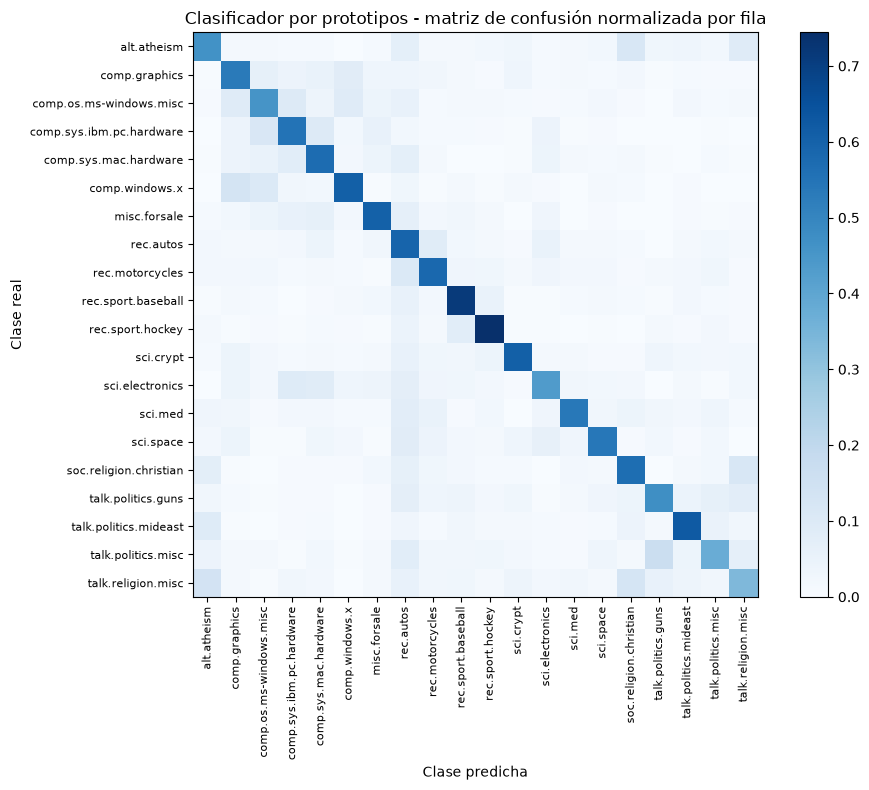

,real,predicha,cantidad
0,talk.politics.misc,talk.politics.guns,51
1,comp.windows.x,comp.graphics,51
2,soc.religion.christian,talk.religion.misc,46
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,44
4,comp.windows.x,comp.os.ms-windows.misc,41
5,rec.motorcycles,rec.autos,41
6,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,38
7,comp.sys.ibm.pc.hardware,comp.sys.mac.hardware,37
8,alt.atheism,soc.religion.christian,37
9,sci.electronics,comp.sys.ibm.pc.hardware,36


In [41]:
f1_por_clase_proto = pd.Series(f1_score(y_test, y_pred_proto, average=None), index=class_names)

cm = confusion_matrix(y_test, y_pred_proto)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap='Blues')
ax.set_xticks(range(20)); ax.set_xticklabels(class_names, rotation=90, fontsize=8)
ax.set_yticks(range(20)); ax.set_yticklabels(class_names, fontsize=8)
ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real')
ax.set_title('Clasificador por prototipos - matriz de confusión normalizada por fila')
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

cm_sin_diag = cm.copy(); np.fill_diagonal(cm_sin_diag, 0)
pares = np.dstack(np.unravel_index(np.argsort(cm_sin_diag.ravel())[::-1][:10], cm.shape))[0]
pd.DataFrame([{'real': class_names[a], 'predicha': class_names[b], 'cantidad': cm_sin_diag[a, b]} for a, b in pares])

Además de la columna de `rec.autos` (correspondiente a los documentos nulos), la matriz presenta bloques en torno a la diagonal. Las principales confusiones se producen entre grupos que comparten vocabulario:

- Grupos `comp.*` entre sí: `windows.x` ↔ `graphics`, `ibm.pc.hardware` ↔ `ms-windows.misc` ↔ `mac.hardware`. Todos tratan sobre software, placas y controladores.
- `talk.politics.misc` → `talk.politics.guns`.
- Religión: `soc.religion.christian` → `talk.religion.misc` y `alt.atheism` → `soc.religion.christian`.
- `rec.motorcycles` → `rec.autos` (motor, ruedas, velocidad).

Las clases con menor F1 son las misceláneas, que reúnen contenido más heterogéneo, y las de religión, cuyos límites temáticos son próximos entre sí. La excepción es `rec.autos` (0.446), tercera desde abajo debido a los 237 documentos nulos: esos falsos positivos reducen su precisión. Las de mejor desempeño son `rec.sport.hockey`, `rec.sport.baseball`, `sci.crypt` y `talk.politics.mideast`, que poseen un vocabulario muy característico (nombres de jugadores, "encryption", "israeli").

In [42]:
f1_por_clase_proto.sort_values().round(3)

talk.religion.misc          0.326
talk.politics.misc          0.411
rec.autos                   0.446
alt.atheism                 0.460
comp.os.ms-windows.misc     0.465
sci.electronics             0.479
comp.graphics               0.503
talk.politics.guns          0.515
comp.sys.mac.hardware       0.536
comp.sys.ibm.pc.hardware    0.536
rec.motorcycles             0.570
soc.religion.christian      0.571
sci.space                   0.595
sci.med                     0.610
misc.forsale                0.614
comp.windows.x              0.616
talk.politics.mideast       0.641
sci.crypt                   0.651
rec.sport.baseball          0.671
rec.sport.hockey            0.722
dtype: float64

### La similaridad máxima como medida de confianza

En el punto 1, el documento con similaridad máxima más baja (4899, con 0.136) fue también uno de los peor emparejados, lo que sugiere que esta medida podría reflejar la confianza del método. Lo verificamos sobre todo el conjunto de test:

In [43]:
aciertos = y_pred_proto == y_test
filas = []
for umbral in [0.0, 0.1, 0.2, 0.3, 0.5]:
    m = sim_max_proto >= umbral
    filas.append({'similaridad máxima >=': umbral, '% de docs de test': m.mean(), 'accuracy en esos docs': aciertos[m].mean()})
pd.DataFrame(filas).round(3)

,similaridad máxima >=,% de docs de test,accuracy en esos docs
0,0.0,1.000,0.552
1,0.1,0.966,0.567
2,0.2,0.544,0.647
3,0.3,0.189,0.748
4,0.5,0.055,0.856


Cuando el vecino más cercano tiene una similaridad ≥ 0.5, el clasificador acierta el 86% de las veces, aunque esto ocurre solo en el 5% de los documentos. Para la mayoría, la similaridad máxima se ubica entre 0.1 y 0.3, rango en el que la tasa de acierto es apenas superior al 50%. Esta medida podría utilizarse para abstenerse de clasificar por debajo de cierto umbral.

### Exploración adicional: k vecinos y centroides

Este análisis excede lo solicitado por la consigna y se incluye como exploración opcional. Dado que 1-NN depende de un único documento de train, evaluamos dos variantes que incorporan más información:

- k-NN: votan los k documentos más similares, ponderados por su similaridad.
- Centroide por clase: se promedian los vectores de train de cada clase y se compara contra esos 20 vectores.

In [44]:
X_train_sim_full = vect_sim.transform(newsgroups_train.data)

def knn_coseno(X_test, X_train, y_train, k, bloque=1000):
    preds = []
    for ini in range(0, X_test.shape[0], bloque):
        S = cosine_similarity(X_test[ini:ini + bloque], X_train)
        top = np.argsort(-S, axis=1)[:, :k]
        for fila, vecinos in enumerate(top):
            preds.append(np.bincount(y_train[vecinos], weights=S[fila, vecinos], minlength=20).argmax())
    return np.array(preds)

filas = [{'variante': '1-NN (prototipos, consigna)', 'F1 macro': f1_score(y_test, y_pred_proto, average='macro')}]
for k in [5, 10, 30]:
    filas.append({'variante': f'{k}-NN ponderado', 'F1 macro': f1_score(y_test, knn_coseno(X_test_sim, X_train_sim_full, y_train, k), average='macro')})

centroides = normalize(np.vstack([np.asarray(X_train_sim_full[y_train == c].mean(axis=0)) for c in range(20)]))
pred_centroide = np.asarray((X_test_sim @ centroides.T).argmax(axis=1)).ravel()
filas.append({'variante': 'Centroide por clase', 'F1 macro': f1_score(y_test, pred_centroide, average='macro')})
pd.DataFrame(filas).round(4)

,variante,F1 macro
0,"1-NN (prototipos, consigna)",0.5469
1,5-NN ponderado,0.6088
2,10-NN ponderado,0.6435
3,30-NN ponderado,0.6680
4,Centroide por clase,0.6623


Con 30 vecinos el F1 asciende de 0.547 a 0.668, y con centroides alcanza 0.662 comparando contra 20 vectores en lugar de 11.314. Interpretamos que un único vecino arrastra todo su ruido, mientras que el promedio de muchos documentos lo atenúa.

### Conclusiones del punto 2

- El clasificador por prototipos supera ampliamente al azar (F1 macro 0.547 frente a aproximadamente 0.05) sin requerir entrenamiento, lo que muestra que TF-IDF con similaridad coseno captura buena parte del tema.
- Falla en tres situaciones: documentos sin vocabulario (que se asignan a la clase del documento 0), clases que comparten vocabulario (grupos `comp.*`, religión, política) y casos en que el vecino más cercano coincide por motivos superficiales.
- Es computacionalmente costoso, ya que cada documento debe compararse con todo el conjunto de train. Además depende de un único vecino; considerar k vecinos o centroides mejora el F1 en aproximadamente 12 puntos.

---
## **3. Naïve Bayes: maximización del F1 macro**

El baseline de la plantilla (`TfidfVectorizer()` + `MultinomialNB()` con valores por defecto) obtiene un F1 macro de 0.585. El objetivo es mejorarlo modificando parámetros del vectorizador y del modelo, y comparar `MultinomialNB` con `ComplementNB`.

### Exploración inicial

Naïve Bayes asume que las palabras son condicionalmente independientes dada la clase (de ahí "naive"), lo que es coherente con una bolsa de palabras: igual que en el punto 1, "Program Manager" se trata como dos términos independientes.

Comenzamos con una tabla reducida para identificar qué parámetros tienen mayor impacto: tipo de vectorizador (conteos o TF-IDF), uso de stopwords, modelo y `alpha`, el parámetro de suavizado aditivo, que evita probabilidades nulas para palabras no observadas (con alpha=1 corresponde al suavizado de Laplace).

In [45]:
def evaluar(vect, modelo):
    Xtr = vect.fit_transform(newsgroups_train.data)
    Xte = vect.transform(newsgroups_test.data)
    modelo.fit(Xtr, y_train)
    return f1_score(y_test, modelo.predict(Xte), average='macro')

filas = []
for nombre_v, vect in [('Count', CountVectorizer()), ('Count + stop', CountVectorizer(stop_words='english')),
                       ('TF-IDF', TfidfVectorizer()), ('TF-IDF + stop', TfidfVectorizer(stop_words='english'))]:
    for nombre_m, Modelo in [('MultinomialNB', MultinomialNB), ('ComplementNB', ComplementNB)]:
        for alpha in [1.0, 0.1, 0.01]:
            filas.append({'vectorizador': nombre_v, 'modelo': nombre_m, 'alpha': alpha,
                          'F1 macro test': evaluar(vect, Modelo(alpha=alpha))})

tabla_exploracion = pd.DataFrame(filas)
tabla_exploracion.pivot_table(index=['vectorizador', 'alpha'], columns='modelo', values='F1 macro test').round(4)

modelo               ComplementNB  MultinomialNB
vectorizador  alpha                             
Count         0.01         0.6235         0.6204
              0.10         0.6386         0.6227
              1.00         0.6374         0.5121
Count + stop  0.01         0.6237         0.6269
              0.10         0.6404         0.6320
              1.00         0.6433         0.5968
TF-IDF        0.01         0.6689         0.6829
              0.10         0.6954         0.6565
              1.00         0.6930         0.5854
TF-IDF + stop 0.01         0.6652         0.6844
              0.10         0.6919         0.6726
              1.00         0.6936         0.6468

En la tabla se observa lo siguiente:

- TF-IDF supera a los conteos en todos los casos, aunque en teoría Multinomial NB está formulado para conteos. El IDF reduce el peso de las palabras omnipresentes, de modo que la evidencia de cada documento queda dominada por términos que sí distinguen clases.
- `alpha` es el parámetro de mayor impacto en MultinomialNB: con TF-IDF el F1 pasa de 0.585 (alpha=1, el baseline) a 0.683 (alpha=0.01). Con TF-IDF cada peso es menor a 1 y la mayoría de las 100.000 palabras aparece en pocos documentos de cada clase, por lo que la suma de pesos de una palabra en una clase suele ser pequeña. Con alpha=1 se suma a cada palabra una pseudo-cuenta que, en la mayoría de los casos, supera su peso real; el suavizado aplana las distribuciones y el modelo pierde información.
- ComplementNB es mucho menos sensible a alpha en este rango (0.01 a 1) y con alpha=1 ya alcanza 0.69. Este comportamiento se analiza más adelante.
- Las stopwords mejoran a MNB con alpha alto (0.585 → 0.647), pero con un alpha adecuado o con CNB prácticamente no modifican el resultado. Naïve Bayes asigna a estas palabras probabilidades similares en todas las clases, por lo que tienen poca influencia en la decisión.

### Búsqueda de hiperparámetros con validación cruzada

La tabla anterior, al igual que la comparación de vectorizadores del punto 2, se evaluó directamente sobre test, según lo propuesto por la consigna. Para la búsqueda más amplia optamos por no seleccionar en función de test, dado que, con 288 combinaciones, elegir la mejor sobre ese conjunto produciría una estimación optimista. Por ello los hiperparámetros se seleccionan mediante validación cruzada de 3 folds sobre train y luego se evalúan en test los modelos elegidos. Se utiliza un `Pipeline` para que el vectorizador se ajuste dentro de cada fold.

La grilla comprende 288 combinaciones (x 3 folds) y su ejecución demora alrededor de 2 minutos.

In [46]:
pipe = Pipeline([('vect', TfidfVectorizer()), ('clf', MultinomialNB())])

grilla = {
    'vect__stop_words': [None, 'english'],
    'vect__min_df': [1, 2, 5],
    'vect__max_df': [1.0, 0.5],
    'vect__sublinear_tf': [False, True],
    'clf': [MultinomialNB(), ComplementNB()],
    'clf__alpha': [0.003, 0.01, 0.03, 0.1, 0.3, 1.0],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
gs = GridSearchCV(pipe, grilla, scoring='f1_macro', cv=cv, n_jobs=-1)

inicio = time.time()
gs.fit(newsgroups_train.data, y_train)
print(f'Grilla terminada en {time.time() - inicio:.0f} s')

Grilla terminada en 113 s


In [47]:
res = pd.DataFrame(gs.cv_results_)
res['modelo'] = res['param_clf'].map(lambda m: type(m).__name__)
columnas = ['modelo', 'param_clf__alpha', 'param_vect__stop_words', 'param_vect__min_df',
            'param_vect__max_df', 'param_vect__sublinear_tf', 'mean_test_score']
res[columnas].sort_values('mean_test_score', ascending=False).head(10).round(4)

,modelo,param_clf__alpha,param_vect__stop_words,param_vect__min_df,param_vect__max_df,param_vect__sublinear_tf,mean_test_score
255,ComplementNB,0.3,english,1,0.5,True,0.7564
243,ComplementNB,0.3,english,1,1.0,True,0.7564
241,ComplementNB,0.3,NaN,1,1.0,True,0.7561
253,ComplementNB,0.3,NaN,1,0.5,True,0.7555
252,ComplementNB,0.3,NaN,1,0.5,False,0.7549
254,ComplementNB,0.3,english,1,0.5,False,0.7548
242,ComplementNB,0.3,english,1,1.0,False,0.7548
240,ComplementNB,0.3,NaN,1,1.0,False,0.7538
216,ComplementNB,0.1,NaN,1,1.0,False,0.7538
228,ComplementNB,0.1,NaN,1,0.5,False,0.7537


In [48]:
# mejor combinación de cada modelo por separado
mejores = res.loc[res.groupby('modelo')['mean_test_score'].idxmax(), columnas]
mejores.round(4)

,modelo,param_clf__alpha,param_vect__stop_words,param_vect__min_df,param_vect__max_df,param_vect__sublinear_tf,mean_test_score
243,ComplementNB,0.30,english,1,1.0,True,0.7564
26,MultinomialNB,0.01,english,1,1.0,False,0.7471


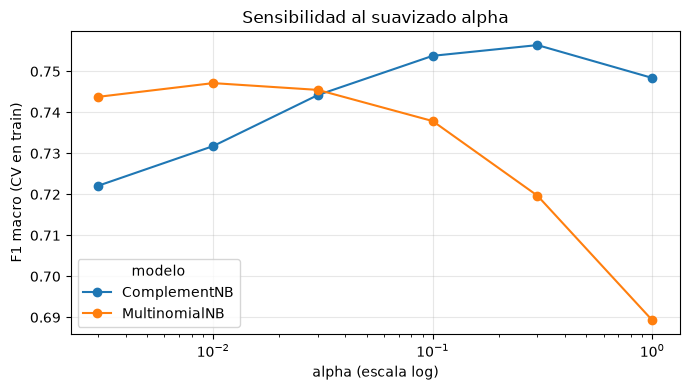

In [49]:
# cómo varía el F1 de CV con alpha, para cada modelo (mejor configuración del vectorizador en cada alpha)
curva = res.groupby(['modelo', 'param_clf__alpha'])['mean_test_score'].max().unstack(0)
ax = curva.plot(marker='o', logx=True, figsize=(7, 4))
ax.set_xlabel('alpha (escala log)'); ax.set_ylabel('F1 macro (CV en train)')
ax.set_title('Sensibilidad al suavizado alpha')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [50]:
# valores del gráfico y efecto de min_df (mejor F1 de CV para cada valor)
print('F1 macro de CV según alpha:')
print(curva.round(4))
print()
print('F1 macro de CV según min_df:')
print(res.groupby(['modelo', 'param_vect__min_df'])['mean_test_score'].max().unstack(0).round(4))

F1 macro de CV según alpha:
modelo            ComplementNB  MultinomialNB
param_clf__alpha                             
0.003                   0.7221         0.7438
0.010                   0.7318         0.7471
0.030                   0.7442         0.7455
0.100                   0.7538         0.7379
0.300                   0.7564         0.7197
1.000                   0.7484         0.6893

F1 macro de CV según min_df:
modelo              ComplementNB  MultinomialNB
param_vect__min_df                             
1                         0.7564         0.7471
2                         0.7469         0.7417
5                         0.7254         0.7270


El gráfico evidencia la diferencia entre ambos modelos: MultinomialNB alcanza su mejor valor con alpha=0.01 y se degrada notablemente con valores altos (casi 6 puntos entre 0.01 y 1). ComplementNB muestra el comportamiento inverso: se beneficia de valores de alpha más altos, alcanza su máximo en 0.3 y se ve perjudicado por valores muy bajos.

La mejor combinación según la validación cruzada es ComplementNB con alpha=0.3, stopwords y `sublinear_tf=True`. `max_df` prácticamente no tiene efecto: con stopwords el resultado es idéntico (casi no quedan términos presentes en más de la mitad de los documentos) y sin stopwords la diferencia es del orden de 0.001. `sublinear_tf` también tiene un impacto menor, lo que explica las combinaciones empatadas en los primeros lugares. `min_df`, en cambio, conviene mantenerlo en 1: todas las mejores combinaciones lo utilizan y con `min_df=5` el mejor CNB desciende de 0.756 a 0.725. Esto contrasta con lo observado para la similaridad en el punto 1: para Naïve Bayes las palabras raras son muy informativas (una palabra poco frecuente que solo aparece en mensajes de `sci.crypt` constituye un indicio fuerte). A continuación se entrenan los dos mejores modelos con todo el conjunto de train y se evalúan en test:

In [51]:
modelos_finales = {}
filas = []
for _, fila in mejores.iterrows():
    Modelo = MultinomialNB if fila['modelo'] == 'MultinomialNB' else ComplementNB
    p = Pipeline([
        ('vect', TfidfVectorizer(stop_words=fila['param_vect__stop_words'], min_df=fila['param_vect__min_df'],
                                 max_df=fila['param_vect__max_df'], sublinear_tf=fila['param_vect__sublinear_tf'])),
        ('clf', Modelo(alpha=fila['param_clf__alpha'])),
    ]).fit(newsgroups_train.data, y_train)
    modelos_finales[fila['modelo']] = p
    filas.append({'modelo': fila['modelo'], 'F1 macro CV (train)': fila['mean_test_score'],
                  'F1 macro test': f1_score(y_test, p.predict(newsgroups_test.data), average='macro')})
pd.DataFrame(filas).round(4)

,modelo,F1 macro CV (train),F1 macro test
0,ComplementNB,0.7564,0.6979
1,MultinomialNB,0.7471,0.6844


En test el mejor modelo es ComplementNB, con un F1 macro de 0.698, frente a 0.684 del mejor MultinomialNB y 0.585 del baseline de la plantilla, lo que representa una mejora de aproximadamente 11 puntos.

El F1 obtenido en validación cruzada (0.747 a 0.756) es considerablemente mayor que el de test (0.684 a 0.698). Una posible explicación es la construcción del dataset: se trata de la versión *"bydate"*, en la que los mensajes de test son posteriores en el tiempo a los de train. En la validación cruzada, en cambio, los mensajes de train se distribuyen al azar, por lo que un mensaje y su respuesta (como los de "hudson" en el punto 1) pueden quedar uno en el fold de entrenamiento y otro en el de validación, lo que facilitaría la validación respecto del test. No verificamos esta hipótesis (requeriría construir folds que respeten fechas o hilos). El orden relativo de los modelos se mantiene, que es lo relevante para la selección.

### Ventaja de ComplementNB sobre MultinomialNB

MultinomialNB estima, para cada clase, la distribución de palabras utilizando únicamente los documentos de esa clase. ComplementNB procede de forma inversa: para cada clase estima la distribución de palabras de todos los documentos que no pertenecen a ella (el "complemento") y asigna la clase cuyo complemento explica peor el documento. Esto tiene dos ventajas:

1. Cada estimación utiliza alrededor de 19 veces más datos (todas las demás clases), por lo que debería ser más estable. Esto podría explicar en parte su distinto comportamiento frente a alpha, aunque no lo verificamos.
2. Es menos sensible al desbalance: en MNB las clases minoritarias (`talk.religion.misc` tiene 377 documentos) tienen estimaciones más ruidosas y el modelo tiende a favorecer a las clases mayoritarias. El uso del complemento atenúa este efecto, que es precisamente lo que la documentación de sklearn indica que resuelve ComplementNB (Rennie et al., 2003).

### Otras variantes evaluadas

El stemming y la limpieza de texto son técnicas habituales del PLN clásico, por lo que evaluamos su efecto sobre la mejor configuración:

In [52]:
from nltk.stem import SnowballStemmer

stemmer = SnowballStemmer('english')
patron_letras = re.compile(r'(?u)\b[a-zA-Z]{2,}\b')
_cache_stem = {}

def analizador_stem(doc):
    """minúsculas + solo palabras de letras + sin stopwords + stemming (con caché para acelerar el cálculo)."""
    tokens = []
    for w in patron_letras.findall(doc.lower()):
        if w in ENGLISH_STOP_WORDS:
            continue
        if w not in _cache_stem:
            _cache_stem[w] = stemmer.stem(w)
        tokens.append(_cache_stem[w])
    return tokens

variantes = {
    'Mejor de la grilla (CNB a=0.3, stop, sublinear)': (TfidfVectorizer(stop_words='english', sublinear_tf=True), ComplementNB(alpha=0.3)),
    'Solo palabras de letras (sin números)': (TfidfVectorizer(stop_words='english', sublinear_tf=True, token_pattern=r'(?u)\b[a-zA-Z]{2,}\b'), ComplementNB(alpha=0.3)),
    'Stemming (Snowball)': (TfidfVectorizer(analyzer=analizador_stem, sublinear_tf=True), ComplementNB(alpha=0.3)),
    'CNB con norm=True': (TfidfVectorizer(stop_words='english', sublinear_tf=True), ComplementNB(alpha=0.3, norm=True)),
    'CountVectorizer binario + MNB': (CountVectorizer(stop_words='english', binary=True), MultinomialNB(alpha=0.1)),
}

filas = []
for nombre, (v, m) in variantes.items():
    p = Pipeline([('vect', v), ('clf', m)])
    f1_cv = cross_val_score(p, newsgroups_train.data, y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
    p.fit(newsgroups_train.data, y_train)
    filas.append({'variante': nombre, 'F1 macro CV': f1_cv,
                  'F1 macro test': f1_score(y_test, p.predict(newsgroups_test.data), average='macro')})
pd.DataFrame(filas).round(4)

,variante,F1 macro CV,F1 macro test
0,"Mejor de la grilla (CNB a=0.3, stop, sublinear)",0.7564,0.6979
1,Solo palabras de letras (sin números),0.7504,0.6947
2,Stemming (Snowball),0.7413,0.6927
3,CNB con norm=True,0.7526,0.6950
4,CountVectorizer binario + MNB,0.6908,0.6344


Ninguna variante mejora la mejor configuración. El stemming incluso empeora levemente el resultado (0.698 → 0.693). Esa variante también elimina los números (utiliza el mismo patrón de solo letras), por lo que debe compararse con la fila "solo palabras de letras" (0.695): el efecto propio del stemming es de apenas 0.002, una diferencia que podría deberse a variabilidad. Una posible explicación es que, en este corpus, lo que se gana al agrupar palabras por su raíz se compensa con lo que se pierde al unificar formas utilizadas en contextos distintos (por ejemplo, "windows" pasa a ser "window"). No evaluamos lematización, que podría permitir una normalización más precisa que el stemming. Eliminar los números tampoco mejora el resultado, ya que algunos son muy informativos ("486" y "386" son procesadores; "c650", un modelo de Mac). La normalización de pesos de ComplementNB (`norm=True`), propuesta en el trabajo original de Rennie et al., tampoco aporta mejoras (0.695).

La variante binaria (`CountVectorizer(binary=True)` + MultinomialNB) queda bastante por debajo de la mejor (0.634), pero esa comparación modifica simultáneamente la representación, el modelo y alpha. Frente a su equivalente con conteos de la primera tabla (Count + stop, MNB, alpha=0.1: 0.632) el resultado es prácticamente igual, por lo que no es posible afirmar que la presencia/ausencia sea inferior a las frecuencias. Lo que sí marca la diferencia es el uso de TF-IDF y de ComplementNB. Además, esta variante no equivale a `BernoulliNB`, que también modela la ausencia de las palabras.

### Comparación final y por clase

In [53]:
mejor_nb = modelos_finales['ComplementNB']
y_pred_nb = mejor_nb.predict(newsgroups_test.data)

resumen = pd.DataFrame([
    {'modelo': 'Azar (uniforme)', 'F1 macro test': f1_score(y_test, DummyClassifier(strategy='uniform', random_state=0).fit(X_dummy_tr, y_train).predict(X_dummy_te), average='macro')},
    {'modelo': 'Prototipos 1-NN (punto 2)', 'F1 macro test': f1_score(y_test, y_pred_proto, average='macro')},
    {'modelo': 'MultinomialNB baseline plantilla', 'F1 macro test': f1_score(y_test, y_pred, average='macro')},
    {'modelo': 'MultinomialNB optimizado', 'F1 macro test': f1_score(y_test, modelos_finales['MultinomialNB'].predict(newsgroups_test.data), average='macro')},
    {'modelo': 'ComplementNB optimizado', 'F1 macro test': f1_score(y_test, y_pred_nb, average='macro')},
])
resumen.round(4)

,modelo,F1 macro test
0,Azar (uniforme),0.0482
1,Prototipos 1-NN (punto 2),0.5469
2,MultinomialNB baseline plantilla,0.5854
3,MultinomialNB optimizado,0.6844
4,ComplementNB optimizado,0.6979


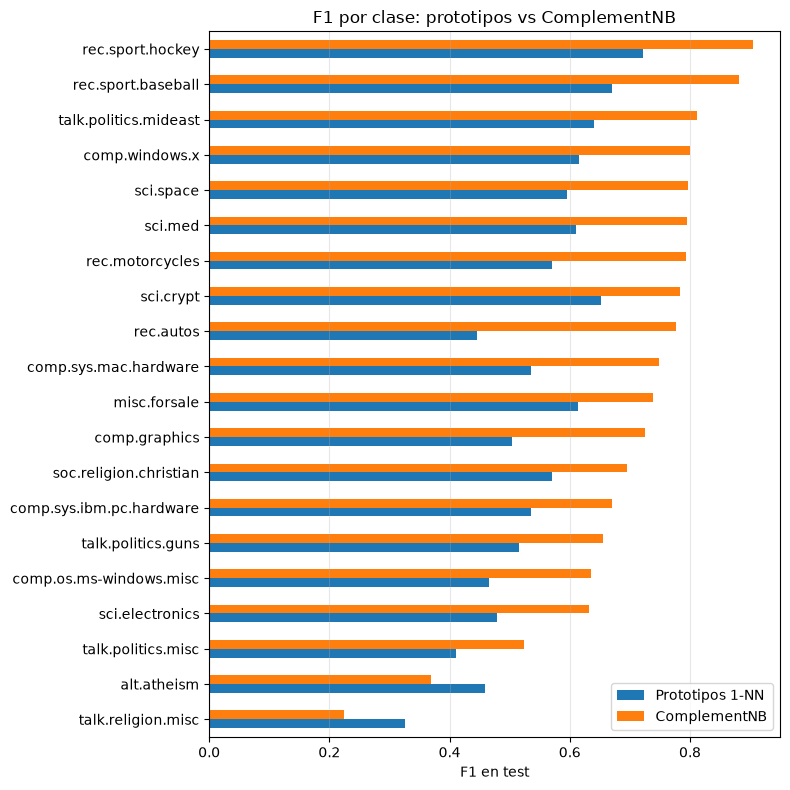

In [54]:
comparacion = pd.DataFrame({
    'Prototipos 1-NN': f1_por_clase_proto,
    'ComplementNB': pd.Series(f1_score(y_test, y_pred_nb, average=None), index=class_names),
}).sort_values('ComplementNB')

ax = comparacion.plot.barh(figsize=(8, 8))
ax.set_xlabel('F1 en test'); ax.set_title('F1 por clase: prototipos vs ComplementNB')
ax.grid(axis='x', alpha=0.3); plt.tight_layout(); plt.show()

In [55]:
f1_nb = comparacion['ComplementNB']
f1_pr = comparacion['Prototipos 1-NN']
print(f'Clases en las que ComplementNB supera a prototipos: {(f1_nb > f1_pr).sum()} de 20')
print(f'Excepciones: {list(comparacion.index[f1_nb < f1_pr])}')

idx_rel = class_names.index('talk.religion.misc')
idx_chr = class_names.index('soc.religion.christian')
m_rel = y_test == idx_rel
y_pred_mnb = modelos_finales['MultinomialNB'].predict(newsgroups_test.data)
print(f'Recall de talk.religion.misc: ComplementNB {(y_pred_nb[m_rel] == idx_rel).mean():.3f} | MultinomialNB {(y_pred_mnb[m_rel] == idx_rel).mean():.3f}')
print(f'Docs de talk.religion.misc que ComplementNB asigna a soc.religion.christian: {(y_pred_nb[m_rel] == idx_chr).mean():.1%}')

Clases en las que ComplementNB supera a prototipos: 18 de 20
Excepciones: ['talk.religion.misc', 'alt.atheism']


Recall de talk.religion.misc: ComplementNB 0.143 | MultinomialNB 0.215
Docs de talk.religion.misc que ComplementNB asigna a soc.religion.christian: 42.2%


### Conclusiones del punto 3

- El F1 macro pasó de 0.585 (baseline) a 0.698 con ComplementNB, alpha=0.3, stopwords y `sublinear_tf`. Los factores de mayor impacto fueron el uso de TF-IDF en lugar de conteos, la elección de alpha y conservar los términos raros (`min_df=1`). Stopwords, `max_df` y `sublinear_tf` aportan poco, y ComplementNB agrega una mejora adicional menor sobre el mejor MultinomialNB (0.698 frente a 0.684).
- Naïve Bayes supera con claridad al clasificador por prototipos (0.698 frente a 0.547) en 18 de las 20 clases. Esto es coherente con que NB utiliza la información de todos los documentos de cada clase, mientras que 1-NN depende de uno solo. Además, la predicción con NB es inmediata y no requiere almacenar ni recorrer el conjunto de train.
- Las dos excepciones son `talk.religion.misc` y `alt.atheism`, donde el clasificador por prototipos supera a NB. Según las predicciones, ComplementNB acierta solo el 14% de los documentos de `talk.religion.misc` y asigna el 42% a `soc.religion.christian` (el mejor MultinomialNB muestra un comportamiento similar, con un recall de 21%). Esto parece contradecir lo señalado sobre la ventaja de CNB con clases minoritarias. Nuestra hipótesis es que el problema obedece más al vocabulario que al tamaño de la clase: ambas clases utilizan prácticamente las mismas palabras (god, jesus, bible) y `soc.religion.christian` lo hace de forma más consistente, por lo que, al resumir cada clase en una única distribución, NB tiende a preferirla. No lo verificamos más allá del análisis de las predicciones. El clasificador 1-NN, en cambio, puede acertar si encuentra un mensaje cercano de la misma discusión (como los de "hudson" en el punto 1), aunque sea por un motivo superficial.
- Las clases difíciles coinciden en ambos modelos: `talk.religion.misc`, `alt.atheism` y `talk.politics.misc`. Algunas tienen límites temáticos muy próximos a otras clases (religión con religión, política con política) y las categorías `misc` reúnen contenido más heterogéneo. Que ambos modelos fallen en las mismas clases sugiere que el solapamiento temático contribuye a los errores, aunque también intervienen la representación y la regla de decisión de cada modelo.
- Los hiperparámetros de la grilla se seleccionaron mediante validación cruzada sobre train (las tablas exploratorias sí utilizan test, según lo propuesto por la consigna). El F1 de validación cruzada resultó mayor que el de test; planteamos una hipótesis al respecto, pero no fue verificada.

---
## **4. Matriz término-documento: similaridad entre palabras**

Al transponer la matriz documento-término, cada fila pasa a representar una palabra y cada columna uno de los 11.314 documentos de train. El vector de una palabra indica en qué documentos aparece y con qué peso, de modo que dos palabras resultan similares si aparecen en los mismos documentos.

Se trata de una versión elemental de la hipótesis distribucional (en línea con Wittgenstein: el significado de una palabra está dado por su uso), según la cual una palabra se conoce por las palabras que la acompañan, con la diferencia de que aquí el contexto es el documento completo y no una ventana de pocas palabras como en Word2Vec o GloVe.

Utilizamos TF-IDF con stopwords, `sublinear_tf` y `min_df=5`. El parámetro `min_df=5` evita que palabras presentes en 1 o 2 documentos aparezcan entre los vecinos: una palabra rara que comparte un único documento con la palabra consultada puede obtener un coseno relativamente alto sin ser representativa de su uso. (Con `min_df=1`, entre los vecinos de "car" aparecía "criterium", presente en un único mensaje.)

In [56]:
vect_pal = TfidfVectorizer(stop_words='english', sublinear_tf=True, min_df=5)
X_pal = vect_pal.fit_transform(newsgroups_train.data)
X_pal_T = X_pal.T.tocsr()          # matriz término-documento
vocab_pal = vect_pal.get_feature_names_out()
word2idx = vect_pal.vocabulary_

print(f'Matriz documento-término: {X_pal.shape}')
print(f'Matriz término-documento: {X_pal_T.shape}')

Matriz documento-término: (11314, 17797)
Matriz término-documento: (17797, 11314)


In [57]:
# comparación con min_df=1: vecinos de "car" y frecuencia documental de "criterium"
vect_pal_1 = TfidfVectorizer(stop_words='english', sublinear_tf=True, min_df=1)
X_pal_1_T = vect_pal_1.fit_transform(newsgroups_train.data).T.tocsr()
vocab_1, w2i_1 = vect_pal_1.get_feature_names_out(), vect_pal_1.vocabulary_
s_car = cosine_similarity(X_pal_1_T[w2i_1['car']], X_pal_1_T).ravel()
s_car[w2i_1['car']] = -1
print('Vecinos de "car" con min_df=1:', [(vocab_1[j], round(float(s_car[j]), 3)) for j in np.argsort(s_car)[::-1][:5]])
print('Documentos que contienen "criterium":', X_pal_1_T[w2i_1['criterium']].nnz)

Vecinos de "car" con min_df=1: [('cars', 0.191), ('dealer', 0.18), ('civic', 0.172), ('owner', 0.169), ('criterium', 0.145)]
Documentos que contienen "criterium": 1


In [58]:
def palabras_similares(palabra, k=5):
    i = word2idx[palabra]
    sims = cosine_similarity(X_pal_T[i], X_pal_T).ravel()
    sims[i] = -1
    top = np.argsort(sims)[::-1][:k]
    return [(vocab_pal[j], round(sims[j], 3)) for j in top]

Las palabras se eligieron manualmente, procurando que cada una ilustre un aspecto distinto:

- car: una palabra concreta de un tema definido (`rec.autos`).
- encryption: un término técnico de `sci.crypt`.
- mouse: una palabra polisémica (animal y dispositivo). En embeddings preentrenados sobre corpus generales, "mouse" puede quedar más cerca de "cat" que del dispositivo, y nos interesó analizar su comportamiento en este corpus.
- nasa: un nombre propio, correspondiente a una organización.
- good: una palabra general, no asociada a ningún tema en particular.

In [59]:
palabras_elegidas = ['car', 'encryption', 'mouse', 'nasa', 'good']

filas = []
for p in palabras_elegidas:
    docs_con_p = X_pal_T[word2idx[p]].nnz
    filas.append({'palabra': p, 'aparece en (docs)': docs_con_p,
                  '5 más similares (coseno)': palabras_similares(p)})
pd.DataFrame(filas)

,palabra,aparece en (docs),5 más similares (coseno)
0,car,396,"[(cars, 0.195), (dealer, 0.186), (civic, 0.166), (owner, 0.155), (engine, 0.144)]"
1,encryption,169,"[(encrypted, 0.338), (clipper, 0.319), (privacy, 0.279), (scheme, 0.265), (secure, 0.263)]"
2,mouse,131,"[(com1, 0.22), (com2, 0.205), (logitech, 0.182), (button, 0.182), (com3, 0.18)]"
3,nasa,157,"[(gov, 0.44), (larc, 0.357), (44135, 0.351), (ames, 0.35), (lerc, 0.334)]"
4,good,1579,"[(luck, 0.265), (don, 0.179), (just, 0.168), (like, 0.165), (think, 0.164)]"


**car** → cars, dealer, civic, owner, engine. Todos los vecinos son pertinentes: el plural, el concesionario, un modelo (Honda Civic), el propietario y el motor. Lo que se captura es una relación temática (palabras que se utilizan al hablar de automóviles) y no sinonimia. Se observa además una limitación: "car" y "cars" tienen vectores distintos. Un stemmer los unificaría, aunque en el punto 3 se vio que el stemming no mejora la clasificación.

**encryption** → encrypted, clipper, privacy, scheme, secure. "clipper" no guarda, por sí misma, relación con la criptografía, pero en 1993 el *Clipper chip* era el principal tema de debate en `sci.crypt`. El método refleja el contexto histórico del corpus y no el significado general de la palabra.

**mouse** → com1, com2, logitech, button, com3. Los vecinos obtenidos para "mouse" corresponden al sentido de dispositivo: puertos serie (COM1, COM2), la marca Logitech y los botones. Esto contrasta con lo que ocurre en embeddings preentrenados sobre corpus generales, donde "mouse" puede quedar cerca de "cat". Lo aprendido depende del corpus: en estos foros predomina el sentido de dispositivo. Además, al existir un único vector por palabra, la polisemia no se resuelve: si el corpus combinara ambos sentidos, se obtendría un vector intermedio entre los dos.

**nasa** → gov, larc, 44135, ames, lerc. Todos los vecinos provienen de firmas y direcciones de correo que no fueron eliminadas por `remove=('footers',)`: "gov" proviene de `nasa.gov`, mientras que "larc", "ames" y "lerc" corresponden a centros de la NASA (Langley, Ames y Lewis) que aparecen en direcciones como `lerc.nasa.gov` o `ames.arc.nasa.gov`. 44135 es el código postal de Cleveland incluido en las firmas de los empleados del centro Lewis (*"NASA Lewis Research Center, Cleveland, Ohio 44135"*). No son palabras semánticamente similares a "nasa", sino palabras que aparecen sistemáticamente junto a ella en las firmas. Con este método, la coocurrencia en los mismos documentos no implica similitud de significado.

**good** → luck, don, just, like, think. "good" aparece en una gran cantidad de documentos de todos los temas, por lo que sus vecinos son otras palabras igualmente genéricas. "luck" aparece en primer lugar por la expresión "good luck" (una colocación, no un sinónimo). "don" corresponde a "don't" segmentado por el tokenizador, que corta en el apóstrofo y descarta la "t" por tener una sola letra. Con excepción de "luck", los vecinos de una palabra sin tema propio aportan poca información.

### Conclusiones del punto 4

- La matriz transpuesta produce vectores de palabras que capturan cierta información: para palabras de un tema específico (car, encryption, mouse) los vecinos son razonables. Sin embargo, lo que se captura es coocurrencia temática y no similitud de significado: aparecen plurales, marcas, colocaciones ("good luck") y firmas de correo.
- El método funciona adecuadamente con palabras temáticas y de forma deficiente con palabras generales, presentes en todo tipo de documentos.
- Los resultados dependen del corpus: "mouse" es un periférico y "clipper" se asocia a la criptografía porque ese era su uso en estos foros en 1993.
- En comparación con embeddings densos como Word2Vec, GloVe o FastText, este método genera vectores de 11.314 dimensiones (una por documento), esparsos y dependientes del conjunto de documentos; los embeddings densos utilizan una dimensionalidad que se define al construir el modelo (por ejemplo, 50 dimensiones en `glove.twitter.27B.50d` y 300 en `cc.en.300` de FastText) y se entrenan con una ventana de contexto reducida, lo que les permite capturar relaciones más finas, como sinónimos o analogías. Lo que no resuelven es la polisemia, ya que también asignan un único vector por palabra. Para ello se requieren embeddings contextuales, como los de los modelos basados en Transformers.

---
## **Conclusiones generales**

1. La vectorización TF-IDF combinada con la similaridad coseno es un método simple pero eficaz: los vecinos comparten clase en el 59% de los casos y el clasificador por prototipos alcanza un F1 macro de 0.547 sin entrenamiento, frente a 0.05 del azar.
2. El análisis de los términos que generan cada similitud fue lo que más permitió explicar los resultados: varios aciertos y errores se explican por detalles del texto (nombres, firmas, documentos vacíos o muy breves) más que por su tema.
3. El ajuste del vectorizador (stopwords, `min_df`, `max_df`, `sublinear_tf`) mejora de forma considerable la similaridad entre documentos y el clasificador por prototipos. En Naïve Bayes los factores determinantes son la ponderación TF-IDF, el suavizado alpha y conservar las palabras raras, que para este modelo son informativas; ComplementNB aporta una mejora adicional menor. El mejor modelo alcanzó un F1 macro de 0.698 en test (baseline: 0.585).
4. La ausencia de sinónimos y la alta dimensionalidad de vectores esparsos son las limitaciones que abordan los embeddings densos. El orden de las palabras y la polisemia, en cambio, no se resuelven con embeddings estáticos, sino con modelos de secuencia y embeddings contextuales.